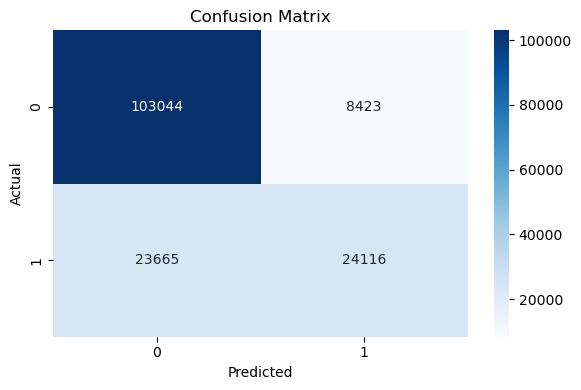

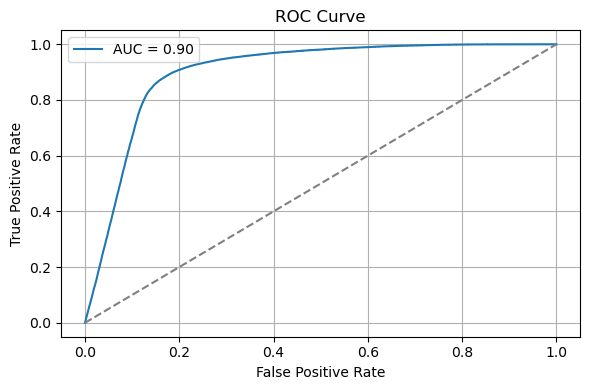


📊 Evaluation Report
Accuracy       : 0.7985
Precision      : 0.7411
Recall         : 0.5047
F1 Score       : 0.6005
ROC AUC Score  : 0.9011

Classification Report:
               precision    recall  f1-score   support

         0.0       0.81      0.92      0.87    111467
         1.0       0.74      0.50      0.60     47781

    accuracy                           0.80    159248
   macro avg       0.78      0.71      0.73    159248
weighted avg       0.79      0.80      0.79    159248



In [3]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------------
# 1. Load Dataset
# -------------------------------
df = pd.read_csv('combined_water_quality_pipeline_data.csv')  # Replace with your actual CSV file

# -------------------------------
# 2. Preprocessing
# -------------------------------
# Separate features
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
categorical_cols.remove('City') if 'City' in categorical_cols else None  # Optional drop if 'City' exists

# Fill numeric missing values
num_imputer = SimpleImputer(strategy='mean')
df[numerical_cols] = num_imputer.fit_transform(df[numerical_cols])

# Encode categorical features
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
    df[col] = LabelEncoder().fit_transform(df[col])

# Split features and target
X = df.drop(columns=['Target'])


# Drop non-numeric columns like 'City'
if 'City' in X.columns:
    X = X.drop(columns=['City'])

y = df['Target']

# Scale numeric features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# -------------------------------
# 3. Train-Test Split
# -------------------------------
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# -------------------------------
# 4. Naive Bayes Model Training
# -------------------------------
model = GaussianNB()
model.fit(X_train, y_train)

# -------------------------------
# 5. Predictions
# -------------------------------
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# -------------------------------
# 6. Evaluation Metrics
# -------------------------------
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, zero_division=0)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
conf_matrix = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)

# -------------------------------
# 7. Plot Confusion Matrix
# -------------------------------
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# -------------------------------
# 8. Plot ROC Curve
# -------------------------------
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------------------
# 9. Display Metrics
# -------------------------------
print("\n📊 Evaluation Report")
print(f"Accuracy       : {acc:.4f}")
print(f"Precision      : {prec:.4f}")
print(f"Recall         : {rec:.4f}")
print(f"F1 Score       : {f1:.4f}")
print(f"ROC AUC Score  : {auc:.4f}")
print("\nClassification Report:\n", report)


In [ ]:
#MultinomialNB and BernoaulliNB


📊 Multinomial Naive Bayes
Accuracy       : 0.6987
Precision      : 0.8242
Recall         : 0.0010
F1 Score       : 0.0021
ROC AUC Score  : 0.7910
Confusion Matrix:
 [[166825     16]
 [ 71956     75]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.70      1.00      0.82    166841
         1.0       0.82      0.00      0.00     72031

    accuracy                           0.70    238872
   macro avg       0.76      0.50      0.41    238872
weighted avg       0.74      0.70      0.58    238872


📊 Bernoulli Naive Bayes
Accuracy       : 0.7019
Precision      : 0.7165
Recall         : 0.0188
F1 Score       : 0.0366
ROC AUC Score  : 0.5886
Confusion Matrix:
 [[166306    535]
 [ 70679   1352]]

Classification Report:
               precision    recall  f1-score   support

         0.0       0.70      1.00      0.82    166841
         1.0       0.72      0.02      0.04     72031

    accuracy                           0.70    238872
   ma

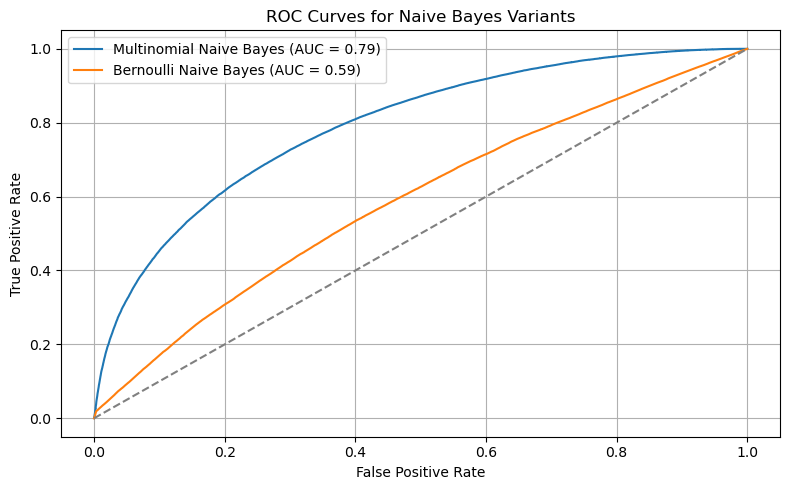

In [5]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.preprocessing import LabelEncoder, MinMaxScaler, Binarizer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt
import seaborn as sns

# -------------------------------
# 1. Load Dataset
# -------------------------------
df = pd.read_csv('combined_water_quality_pipeline_data.csv')  # Replace with your actual dataset

# -------------------------------
# 2. Preprocessing
# -------------------------------
# Drop 'City' if present
if 'City' in df.columns:
    df.drop(columns=['City'], inplace=True)

# Encode categorical features
for col in df.select_dtypes(include='object').columns:
    df[col] = df[col].fillna(df[col].mode()[0])
    df[col] = LabelEncoder().fit_transform(df[col])

# Impute numeric values
imputer = SimpleImputer(strategy='mean')
df[df.columns] = imputer.fit_transform(df)

# -------------------------------
# 3. Feature Engineering
# Normalize for MultinomialNB
X = df.drop(columns=['Target'])
y = df['Target']
scaler = MinMaxScaler()
X_mnb = scaler.fit_transform(X)

# Binarize for BernoulliNB
X_bnb = Binarizer(threshold=0.5).fit_transform(X_mnb)

# Train/test split
X_train_mnb, X_test_mnb, y_train, y_test = train_test_split(X_mnb, y, test_size=0.3, random_state=42)
X_train_bnb, X_test_bnb, _, _ = train_test_split(X_bnb, y, test_size=0.3, random_state=42)

# -------------------------------
# 4. Train Models
# -------------------------------
mnb = MultinomialNB()
mnb.fit(X_train_mnb, y_train)
y_pred_mnb = mnb.predict(X_test_mnb)
y_prob_mnb = mnb.predict_proba(X_test_mnb)[:, 1]

bnb = BernoulliNB()
bnb.fit(X_train_bnb, y_train)
y_pred_bnb = bnb.predict(X_test_bnb)
y_prob_bnb = bnb.predict_proba(X_test_bnb)[:, 1]

# -------------------------------
# 5. Evaluation Function
# -------------------------------
def evaluate_model(y_true, y_pred, y_prob, title):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_prob)
    conf = confusion_matrix(y_true, y_pred)

    print(f"\n📊 {title}")
    print(f"Accuracy       : {acc:.4f}")
    print(f"Precision      : {prec:.4f}")
    print(f"Recall         : {rec:.4f}")
    print(f"F1 Score       : {f1:.4f}")
    print(f"ROC AUC Score  : {auc:.4f}")
    print("Confusion Matrix:\n", conf)
    print("\nClassification Report:\n", classification_report(y_true, y_pred))

    # ROC Curve
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    plt.plot(fpr, tpr, label=f"{title} (AUC = {auc:.2f})")

# -------------------------------
# 6. Run Evaluations
# -------------------------------
plt.figure(figsize=(8, 5))
evaluate_model(y_test, y_pred_mnb, y_prob_mnb, "Multinomial Naive Bayes")
evaluate_model(y_test, y_pred_bnb, y_prob_bnb, "Bernoulli Naive Bayes")

# Finalize ROC plot
plt.plot([0, 1], [0, 1], '--', color='gray')
plt.title("ROC Curves for Naive Bayes Variants")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
#GussianNB with Ensemble BaggingClassifier and SMOTE

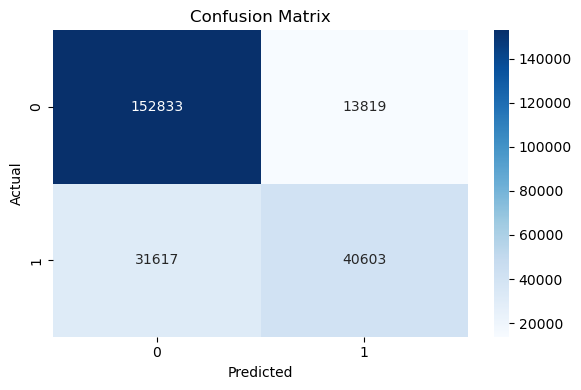

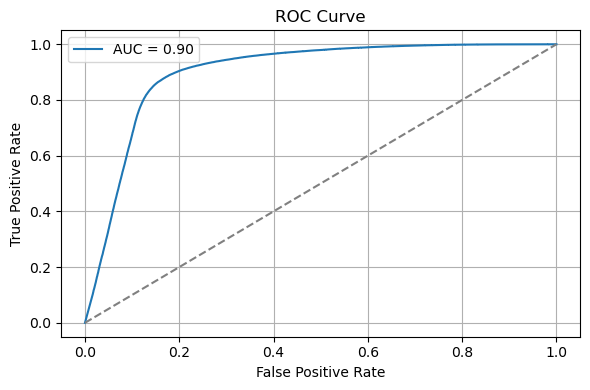


📊 Evaluation Report
Accuracy       : 0.8098
Precision      : 0.7461
Recall         : 0.5622
F1 Score       : 0.6412
ROC AUC Score  : 0.9003

Classification Report:
               precision    recall  f1-score   support

         0.0       0.83      0.92      0.87    166652
         1.0       0.75      0.56      0.64     72220

    accuracy                           0.81    238872
   macro avg       0.79      0.74      0.76    238872
weighted avg       0.80      0.81      0.80    238872



In [11]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
from imblearn.over_sampling import SMOTE
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset
df = pd.read_csv('combined_water_quality_pipeline_data.csv')

# 2. Preprocessing
numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
if 'City' in categorical_cols:
    categorical_cols.remove('City')

# Impute missing values
num_imputer = SimpleImputer(strategy='mean')
df[numerical_cols] = num_imputer.fit_transform(df[numerical_cols])

# Encode categorical
for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])
    df[col] = LabelEncoder().fit_transform(df[col])

# Drop non-feature columns
X = df.drop(columns=['Target'])
if 'City' in X.columns:
    X = X.drop(columns=['City'])

y = df['Target']

# 3. Scale Features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.3, random_state=42, stratify=y
)

# 5. Balance Training Set with SMOTE
smote = SMOTE(random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train, y_train)

# 6. Train Naive Bayes
model = GaussianNB()
model.fit(X_train_balanced, y_train_balanced)

# 7. Predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# 8. Evaluation Metrics
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
conf_matrix = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred)

# 9. Confusion Matrix Plot
plt.figure(figsize=(6, 4))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# 10. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
plt.figure(figsize=(6, 4))
plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 11. Print Evaluation
print("\n📊 Evaluation Report")
print(f"Accuracy       : {acc:.4f}")
print(f"Precision      : {prec:.4f}")
print(f"Recall         : {rec:.4f}")
print(f"F1 Score       : {f1:.4f}")
print(f"ROC AUC Score  : {auc:.4f}")
print("\nClassification Report:\n", report)
